# Procesamiento 3D con datos sintéticos: terraza este (Teyuna)

Este notebook **prueba el diseño** de [design_teyuna_terraces.ipynb](design_teyuna_terraces.ipynb) antes de ir a campo:
1. Toma la geometría de la terraza este del archivo de replanteo (3 tendidos + anillo de golpes).
2. Define un **modelo 3D "verdadero"** del subsuelo: relleno sobre suelo natural, un contacto de profundidad variable, una fosa rellena y un muro enterrado.
3. Calcula los **tiempos de primer arribo sintéticos** y les añade ruido realista.
4. Hace la **inversión tomográfica 3D** con pyGIMLi, igual que se haría con los picks reales.
5. Compara el resultado con el modelo verdadero: **qué se recupera y qué no**.

**Cómo se evita el "crimen inverso"** (usar el mismo cálculo para generar e invertir, lo que da resultados demasiado optimistas):
- Los datos se generan en una malla más fina, con un trazado de rayos más preciso (`secNodes=2`).
- La inversión usa otra malla, más gruesa, con `secNodes=1`.
- Se añade ruido de picado y de trigger.

El tiempo de ejecución es de unos 5–8 minutos.

In [1]:
import os, sys
# tetgen (mallas 3D) está en el bin del entorno; el kernel no siempre lo tiene en el PATH
os.environ["PATH"] = os.path.join(sys.prefix, "bin") + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from pathlib import Path
import pygimli as pg
import pygimli.meshtools as mt
from pygimli.physics import TravelTimeManager
%matplotlib inline
pg.setLogLevel(30)

# --- Diseño (terraza este) ---
STAKEOUT_CSV = "design/teyuna_terraces_stakeout.csv"
SPREADS = ["E000", "E060", "E120"]
RING = "E-anillo"
OVAL = dict(cx=29.0, cy=0.0, a=11.0, b=8.5)
MIN_OFFSET = 0.3                       # m
DOMAIN = dict(x=(16.5, 41.5), y=(-10.0, 10.0), depth=4.5)   # m, volumen modelado

# --- Ruido sintético ---
PICK_NOISE = 0.20e-3       # s, desviación del picado por traza
TRIGGER_JITTER = 0.05e-3   # s, error residual del trigger por posición de golpe (tras alinear golpes)
SEED = 42

# --- Inversión ---
ERR_ABS, ERR_REL = 0.4e-3, 0.01   # error asumido de los tiempos
LAM, Z_WEIGHT, MAX_ITER = 20.0, 0.5, 10
V_TOP, V_BOTTOM = 350.0, 1200.0   # m/s, modelo inicial con gradiente
V_INTERFACE = 700.0               # m/s, isolínea usada para estimar el contacto

VMIN, VMAX, CMAP = 250, 1300, "YlOrBr"
OUT = Path("design/synthetic"); OUT.mkdir(parents=True, exist_ok=True)

## 1. Geometría desde el archivo de replanteo

Cada tendido registra sus golpes en línea y todos los golpes del anillo. Los puntos que coinciden (por ejemplo, un golpe en el sitio de un geófono) se fusionan en un solo sensor.

In [2]:
stake = pd.read_csv(STAKEOUT_CSV)
sensor_id, sensors, pairs, pair_spread = {}, [], [], []

def sid(x, y):
    key = (round(x, 2), round(y, 2))
    if key not in sensor_id:
        sensor_id[key] = len(sensors); sensors.append([key[0], key[1], 0.0])
    return sensor_id[key]

ring_xy = stake[stake.tendido == RING][["x", "y"]].to_numpy()
for sp in SPREADS:
    rows = stake[stake.tendido == sp]
    geo = [sid(x, y) for x, y in rows[rows.tipo == "geófono"][["x", "y"]].to_numpy()]
    shots = [sid(x, y) for x, y in np.vstack([rows[rows.tipo == "golpe línea"][["x", "y"]].to_numpy(), ring_xy])]
    for s in shots:
        for g in geo:
            if np.hypot(*(np.array(sensors[s][:2]) - sensors[g][:2])) > MIN_OFFSET:
                pairs.append((s, g)); pair_spread.append(sp)
sensors = np.array(sensors); pair_spread = np.array(pair_spread)

def make_scheme():
    data = pg.DataContainer()
    for p in sensors: data.createSensor(p)
    data.registerSensorIndex("s"); data.registerSensorIndex("g")
    data.resize(len(pairs))
    data.set("s", [p[0] for p in pairs]); data.set("g", [p[1] for p in pairs])
    return data

offset = np.array([np.hypot(*(sensors[s, :2] - sensors[g, :2])) for s, g in pairs])
print(f"{len(sensors)} posiciones (geófonos + golpes), {len(pairs)} tiempos de arribo, "
      f"offsets {offset.min():.1f}–{offset.max():.1f} m")

93 posiciones (geófonos + golpes), 2217 tiempos de arribo, offsets 0.4–18.6 m


## 2. Modelo verdadero

Un escenario plausible para una terraza, **inventado para la prueba**:
- **Relleno**: 350 m/s, aumentando suavemente con la profundidad.
- **Suelo natural / saprolito**: ~1000 m/s.
- **Contacto relleno/natural**: a 1.2–3.2 m de profundidad. Es más hondo hacia el sur (lado de la ladera, relleno más grueso) y ondula en dirección este–oeste.
- **Fosa rellena** (250 m/s): 3 m de diámetro y 1.8 m de profundidad, en x ≈ 24, y ≈ −3.
- **Muro enterrado** (1300 m/s): 1 m de ancho, entre 0.3 y 1.3 m de profundidad.

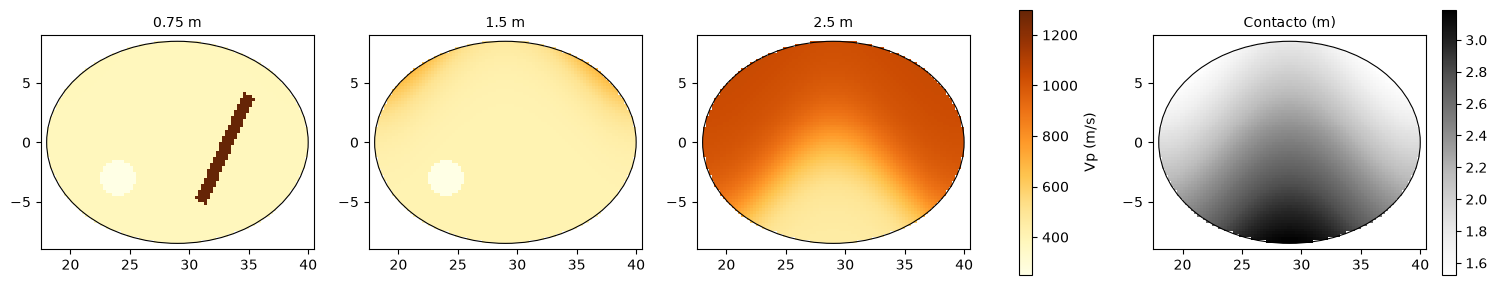

In [3]:
def interface_depth(x, y):
    return 2.2 - 0.7 * (y / 8.5) + 0.3 * np.cos(2 * np.pi * (x - 29) / 22)

PIT = dict(x=24.0, y=-3.0, r=1.5, bottom=1.8)
WALL = dict(p0=(31.0, -5.0), p1=(35.0, 4.0), width=1.0, top=0.3, bottom=1.3)

def v_true(x, y, z):
    d = -np.asarray(z); h = interface_depth(x, y)
    v_fill, v_base = 350 + 40 * d, 1000 + 50 * (d - h)
    v = v_fill + (v_base - v_fill) / (1 + np.exp(-(d - h) / 0.15))
    v = np.where((np.hypot(x - PIT["x"], y - PIT["y"]) < PIT["r"]) & (d < PIT["bottom"]), 250.0, v)
    p0, p1 = np.array(WALL["p0"]), np.array(WALL["p1"])
    u = (p1 - p0) / np.linalg.norm(p1 - p0)
    along = (x - p0[0]) * u[0] + (y - p0[1]) * u[1]
    across = np.abs(-(x - p0[0]) * u[1] + (y - p0[1]) * u[0])
    wall = (along > 0) & (along < np.linalg.norm(p1 - p0)) & (across < WALL["width"] / 2) & (d > WALL["top"]) & (d < WALL["bottom"])
    return np.where(wall, 1300.0, v)

# Rejilla de visualización
xs = np.arange(DOMAIN["x"][0] + 0.125, DOMAIN["x"][1], 0.25)
ys = np.arange(DOMAIN["y"][0] + 0.125, DOMAIN["y"][1], 0.25)
XX, YY = np.meshgrid(xs, ys, indexing="ij")
inside = ((XX - OVAL["cx"]) / OVAL["a"]) ** 2 + ((YY - OVAL["cy"]) / OVAL["b"]) ** 2 <= 1
SLICES = [0.75, 1.5, 2.5]

def oval_outline(ax):
    ax.add_patch(Ellipse((OVAL["cx"], OVAL["cy"]), 2 * OVAL["a"], 2 * OVAL["b"], fill=False, ec="k", lw=0.8))
    ax.set_aspect("equal"); ax.set_xlim(OVAL["cx"] - OVAL["a"] - 0.5, OVAL["cx"] + OVAL["a"] + 0.5)
    ax.set_ylim(-OVAL["b"] - 0.5, OVAL["b"] + 0.5)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), constrained_layout=True)
for ax, z in zip(axes, SLICES):
    im = ax.pcolormesh(xs, ys, np.where(inside, v_true(XX, YY, -z), np.nan).T, cmap=CMAP, vmin=VMIN, vmax=VMAX, shading="nearest")
    oval_outline(ax); ax.set_title(f"{z} m", fontsize=10)
fig.colorbar(im, ax=axes[:3], shrink=0.8, label="Vp (m/s)")
im2 = axes[3].pcolormesh(xs, ys, np.where(inside, interface_depth(XX, YY), np.nan).T, cmap="Greys", shading="nearest")
oval_outline(axes[3]); axes[3].set_title("Contacto (m)", fontsize=10)
fig.colorbar(im2, ax=axes[3], shrink=0.8)
plt.show()

## 3. Datos sintéticos

Los tiempos se calculan con rayos de Dijkstra en una malla tetraédrica **fina**, con un nodo exacto en cada geófono y golpe y `secNodes=2`. Después se añade:
- un error de picado gaussiano de 0.2 ms por traza;
- un error de trigger de 0.05 ms por posición de golpe (el residual tras alinear los golpes individuales, como hicimos en L1).

Opening /tmp/tmpz1vnbf3q.poly.
  Segments are connected properly.


Malla verdadera: 18658 celdas; 2217 tiempos, ruido RMS añadido 0.20 ms


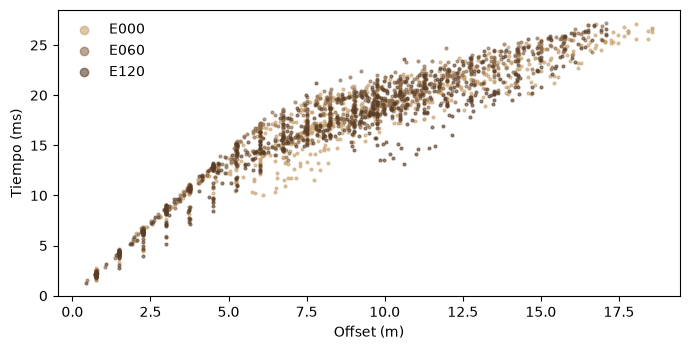

In [4]:
def make_mesh(area, quality, sub_node_depth):
    (x0, x1), (y0, y1), depth = DOMAIN["x"], DOMAIN["y"], DOMAIN["depth"]
    plc = mt.createCube(size=[x1 - x0, y1 - y0, depth], pos=[(x0 + x1) / 2, (y0 + y1) / 2, -depth / 2],
                        marker=1, boundaryMarker=-1)
    for p in sensors:   # nodos exactos en los sensores y uno justo debajo para refinar la superficie
        plc.createNode(p.tolist()); plc.createNode((p - [0, 0, sub_node_depth]).tolist())
    return mt.createMesh(plc, quality=quality, area=area)

true_mesh = make_mesh(area=1.0, quality=1.4, sub_node_depth=0.10)
cc = np.array(true_mesh.cellCenters())
true_velocity = v_true(cc[:, 0], cc[:, 1], cc[:, 2])
data = TravelTimeManager().simulate(mesh=true_mesh, slowness=1 / true_velocity, scheme=make_scheme(),
                                    secNodes=2, noiseLevel=0, noiseAbs=0)

rng = np.random.default_rng(SEED)
t_clean = np.array(data["t"]); shot = np.array(data["s"], int)
jitter = {s: rng.normal(0, TRIGGER_JITTER) for s in np.unique(shot)}
t_obs = t_clean + rng.normal(0, PICK_NOISE, len(t_clean)) + np.array([jitter[s] for s in shot])
data.set("t", t_obs)
data.set("err", ERR_ABS + ERR_REL * t_obs)
data.save(str(OUT / "teyuna_E_synthetic.sgt"))
print(f"Malla verdadera: {true_mesh.cellCount()} celdas; {data.size()} tiempos, "
      f"ruido RMS añadido {np.sqrt(np.mean((t_obs - t_clean) ** 2)) * 1e3:.2f} ms")

fig, ax = plt.subplots(figsize=(7, 3.6))
for sp, color in zip(SPREADS, ["#c8a06e", "#8c6a4a", "#5a3d26"]):
    k = pair_spread == sp
    ax.scatter(offset[k], t_obs[k] * 1e3, s=4, color=color, alpha=0.6, label=sp)
ax.set_xlabel("Offset (m)"); ax.set_ylabel("Tiempo (ms)"); ax.legend(frameon=False, markerscale=3)
plt.tight_layout(); plt.show()

La dispersión vertical para un mismo offset **es la información 3D**: rayos de igual longitud tardan distinto según por dónde pasan (relleno más o menos grueso, fosa, muro).

## 4. Inversión 3D

Se usa una malla **distinta y más gruesa** (`secNodes=1`) y un modelo inicial con gradiente de 350 a 1200 m/s, sin información del modelo verdadero. Es exactamente lo que se haría con los picks reales.

Opening /tmp/tmp3jp1vtgd.poly.
  Segments are connected properly.




Malla de inversión: 12350 celdas | chi² = 0.81, RMS = 0.52 ms, Vp 294–1486 m/s


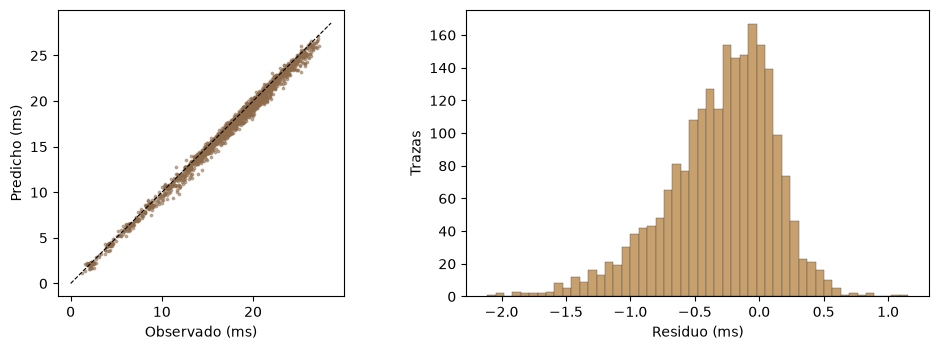

In [5]:
inv_mesh = make_mesh(area=3.0, quality=1.5, sub_node_depth=0.15)
mgr = TravelTimeManager()
velocity = np.array(mgr.invert(data, mesh=inv_mesh, secNodes=1, lam=LAM, zWeight=Z_WEIGHT,
                               vTop=V_TOP, vBottom=V_BOTTOM, maxIter=MAX_ITER, verbose=False))
response = np.array(mgr.inv.response)
para = mgr.paraDomain
coverage = np.array(mgr.fop.jacobian().transMult(pg.Vector(data.size(), 1.0)))  # longitud de rayo por celda
print(f"Malla de inversión: {para.cellCount()} celdas | chi² = {mgr.inv.chi2():.2f}, "
      f"RMS = {np.sqrt(np.mean((response - t_obs) ** 2)) * 1e3:.2f} ms, Vp {velocity.min():.0f}–{velocity.max():.0f} m/s")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.scatter(t_obs * 1e3, response * 1e3, s=3, color="#8c6a4a", alpha=0.5)
lim = [0, t_obs.max() * 1e3 * 1.05]; a1.plot(lim, lim, "k--", lw=0.8)
a1.set_xlabel("Observado (ms)"); a1.set_ylabel("Predicho (ms)"); a1.set_aspect("equal")
a2.hist((response - t_obs) * 1e3, bins=50, color="#c8a06e", ec="0.3", lw=0.3)
a2.set_xlabel("Residuo (ms)"); a2.set_ylabel("Trazas")
plt.tight_layout(); plt.show()

## 5. Verdadero frente a invertido

Cortes horizontales a 0.75, 1.5 y 2.5 m. Se enmascaran las zonas con poca cobertura de rayos y las de fuera de la grama.

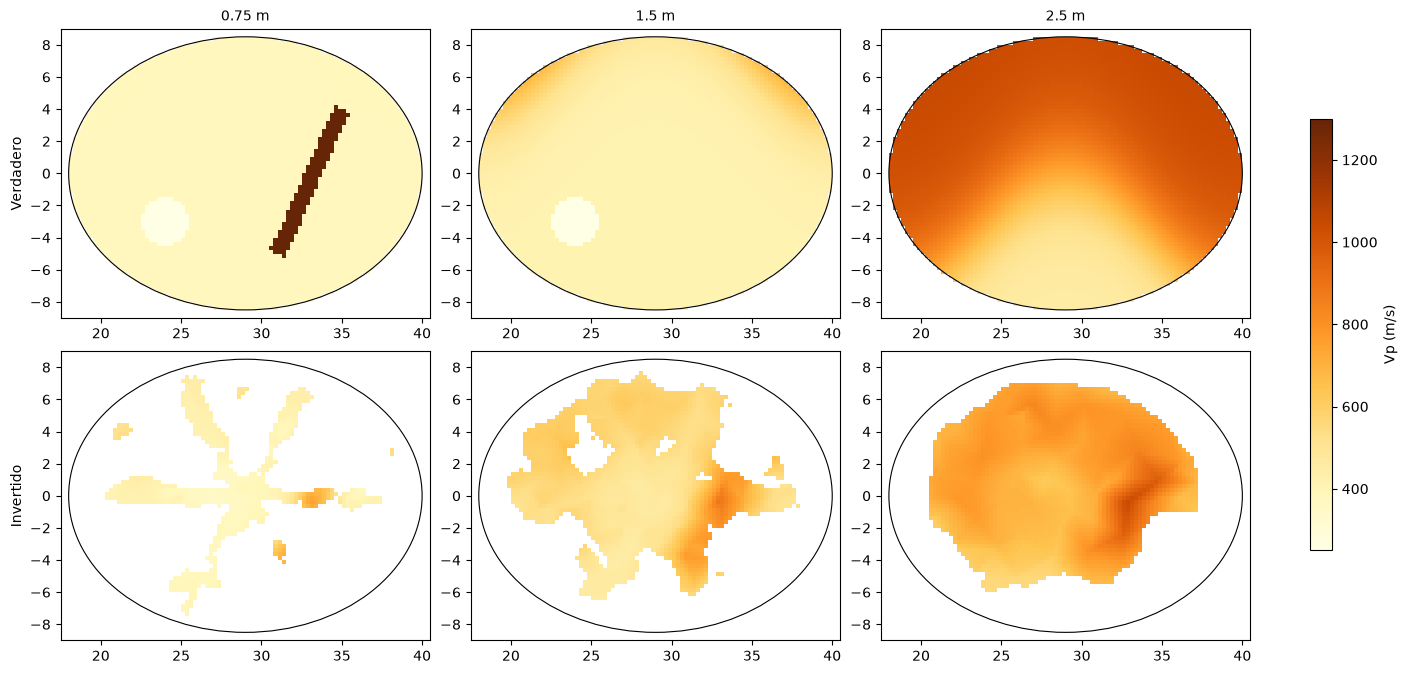

In [6]:
# Valores en los nodos para visualizar sin el mosaico de tetraedros;
# la cobertura nodal es la fracción de celdas vecinas atravesadas por rayos.
v_node = np.array(pg.meshtools.cellDataToNodeData(para, velocity))
cov_node = np.array(pg.meshtools.cellDataToNodeData(para, (coverage > 0).astype(float)))
MIN_COVER = 0.5

def sample(points):
    pos = [pg.Pos(*p) for p in points]
    v = np.array(pg.interpolate(para, v_node, pos)); cov = np.array(pg.interpolate(para, cov_node, pos))
    return np.where(v > 0, v, np.nan), cov

fig, axes = plt.subplots(2, 3, figsize=(14, 6.6), constrained_layout=True)
for j, z in enumerate(SLICES):
    pts = np.c_[XX.ravel(), YY.ravel(), np.full(XX.size, -z)]
    v_inv, cov = sample(pts)
    v_inv = np.where(inside.ravel() & (cov >= MIN_COVER), v_inv, np.nan).reshape(XX.shape)
    for i, field in enumerate([np.where(inside, v_true(XX, YY, -z), np.nan), v_inv]):
        ax = axes[i, j]
        im = ax.pcolormesh(xs, ys, field.T, cmap=CMAP, vmin=VMIN, vmax=VMAX, shading="nearest")
        oval_outline(ax)
        if i == 0: ax.set_title(f"{z} m", fontsize=10)
        if j == 0: ax.set_ylabel(["Verdadero", "Invertido"][i])
fig.colorbar(im, ax=axes, shrink=0.7, label="Vp (m/s)")
plt.show()

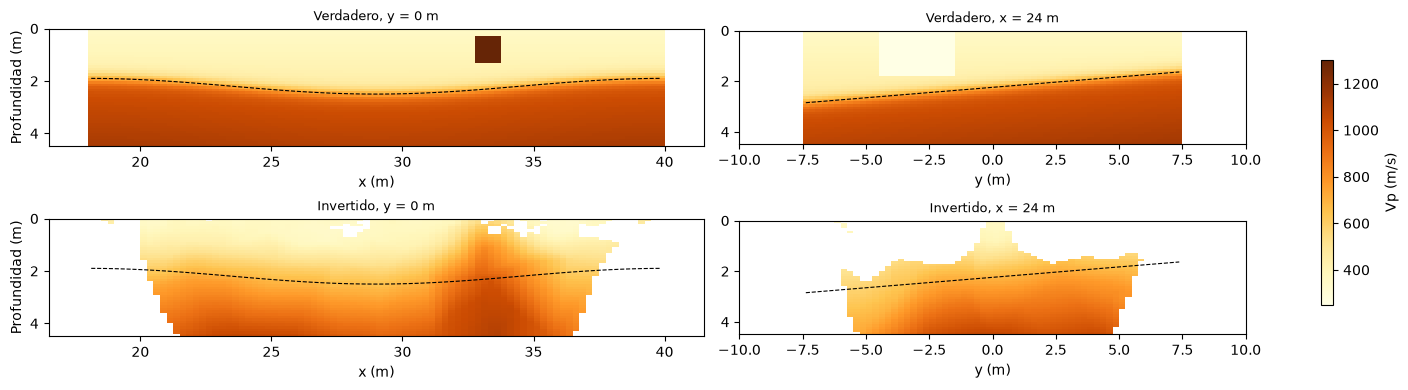

In [7]:
# Sección vertical por el eje largo (y = 0) y por la fosa (x = 24)
zs = np.arange(0.05, DOMAIN["depth"], 0.1)
fig, axes = plt.subplots(2, 2, figsize=(14, 3.8), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2 * OVAL["a"], 2 * OVAL["b"]]})
for j, (label, h_axis, fixed) in enumerate([("y = 0 m", xs, ("y", 0.0)), (f"x = {PIT['x']:.0f} m", ys, ("x", PIT["x"]))]):
    H, Z = np.meshgrid(h_axis, zs, indexing="ij")
    X_, Y_ = (H, np.full_like(H, fixed[1])) if fixed[0] == "y" else (np.full_like(H, fixed[1]), H)
    keep = ((X_ - OVAL["cx"]) / OVAL["a"]) ** 2 + ((Y_ - OVAL["cy"]) / OVAL["b"]) ** 2 <= 1
    v_inv, cov = sample(np.c_[X_.ravel(), Y_.ravel(), -Z.ravel()])
    v_inv = np.where(keep.ravel() & (cov >= MIN_COVER), v_inv, np.nan).reshape(H.shape)
    for i, field in enumerate([np.where(keep, v_true(X_, Y_, -Z), np.nan), v_inv]):
        ax = axes[i, j]
        im = ax.pcolormesh(h_axis, zs, field.T, cmap=CMAP, vmin=VMIN, vmax=VMAX, shading="nearest")
        ax.plot(h_axis, np.where(keep[:, 0], interface_depth(X_[:, 0], Y_[:, 0]), np.nan), "k--", lw=0.8)
        ax.set_ylim(DOMAIN["depth"], 0); ax.set_aspect("equal")
        ax.set_title(f"{['Verdadero', 'Invertido'][i]}, {label}", fontsize=9)
        ax.set_xlabel("x (m)" if fixed[0] == "y" else "y (m)")
    axes[0, j].set_xlim(axes[1, j].get_xlim())
for ax in axes[:, 0]: ax.set_ylabel("Profundidad (m)")
fig.colorbar(im, ax=axes, shrink=0.7, label="Vp (m/s)")
plt.show()

La línea discontinua es el contacto verdadero. El inversor solo ve el contraste de velocidad: **no distingue un muro rápido de un contacto somero**. Por eso el muro aparece "corrido" hacia abajo y unido al suelo natural.

## 6. ¿Se recupera la profundidad del contacto?

En cada columna se toma como contacto la profundidad a la que el modelo invertido supera **700 m/s**, a medio camino entre el relleno y el suelo natural.

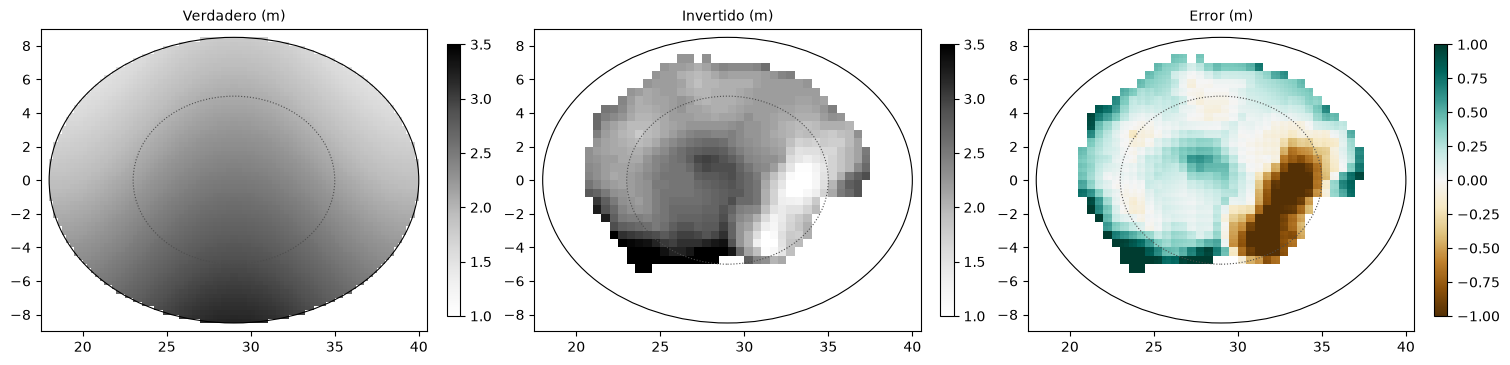

,zona,error mediano (m),|error| mediano (m),|error| P90 (m),sin estimación (%)
0,central (12 × 10 m),0.03,0.18,1.00,1.19
1,toda la grama,0.10,0.22,0.91,45.37


In [8]:
h_true = np.where(inside, interface_depth(XX, YY), np.nan)
h_inv = np.full(XX.shape, np.nan)
zcol = np.arange(0.05, DOMAIN["depth"] - 0.05, 0.05)
for i, j in zip(*np.where(inside[::2, ::2])):
    i2, j2 = 2 * i, 2 * j
    col, cov = sample(np.c_[np.full(len(zcol), XX[i2, j2]), np.full(len(zcol), YY[i2, j2]), -zcol])
    above = np.where((col > V_INTERFACE) & (cov >= MIN_COVER))[0]
    if above.size: h_inv[i2:i2 + 2, j2:j2 + 2] = zcol[above[0]]
h_inv = np.where(inside, h_inv, np.nan)
err = h_inv - h_true
central = inside & (((XX - OVAL["cx"]) / 6) ** 2 + (YY / 5) ** 2 <= 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
for ax, field, title, cmap, lims in [(axes[0], h_true, "Verdadero (m)", "Greys", (1, 3.5)),
                                     (axes[1], h_inv, "Invertido (m)", "Greys", (1, 3.5)),
                                     (axes[2], err, "Error (m)", "BrBG", (-1, 1))]:
    im = ax.pcolormesh(xs, ys, field.T, cmap=cmap, vmin=lims[0], vmax=lims[1], shading="nearest")
    oval_outline(ax); ax.set_title(title, fontsize=10); fig.colorbar(im, ax=ax, shrink=0.8)
for ax in axes: ax.add_patch(Ellipse((OVAL["cx"], OVAL["cy"]), 12, 10, fill=False, ec="0.3", ls=":", lw=0.8))
plt.show()

summary = pd.DataFrame({
    "zona": ["central (12 × 10 m)", "toda la grama"],
    "error mediano (m)": [np.nanmedian(err[central]), np.nanmedian(err[inside])],
    "|error| mediano (m)": [np.nanmedian(np.abs(err[central])), np.nanmedian(np.abs(err[inside]))],
    "|error| P90 (m)": [np.nanpercentile(np.abs(err[central]), 90), np.nanpercentile(np.abs(err[inside]), 90)],
    "sin estimación (%)": [100 * np.isnan(h_inv[central]).mean(), 100 * np.isnan(h_inv[inside]).mean()],
}).round(2)
summary

## 7. Objetos pequeños: fosa y muro

In [9]:
def mean_v(mask_fn, depths):
    pts = np.array([[x, y, -z] for z in depths for x, y in zip(XX[mask_fn], YY[mask_fn])])
    v_inv, _ = sample(pts)
    return v_true(pts[:, 0], pts[:, 1], pts[:, 2]).mean(), np.nanmean(v_inv)

pit_mask = np.hypot(XX - PIT["x"], YY - PIT["y"]) < PIT["r"]
p0, p1 = np.array(WALL["p0"]), np.array(WALL["p1"]); u = (p1 - p0) / np.linalg.norm(p1 - p0)
along = (XX - p0[0]) * u[0] + (YY - p0[1]) * u[1]; across = np.abs(-(XX - p0[0]) * u[1] + (YY - p0[1]) * u[0])
wall_mask = (along > 0) & (along < np.linalg.norm(p1 - p0)) & (across < WALL["width"] / 2)
ring_mask = (np.hypot(XX - PIT["x"], YY - PIT["y"]) > 2.5) & (np.hypot(XX - PIT["x"], YY - PIT["y"]) < 4) & inside

rows = []
for name, mask, depths in [("fosa (0.2–1.6 m)", pit_mask, np.arange(0.2, 1.7, 0.2)),
                           ("alrededor de la fosa", ring_mask, np.arange(0.2, 1.7, 0.2)),
                           ("muro (0.4–1.2 m)", wall_mask, np.arange(0.4, 1.3, 0.2))]:
    vt, vi = mean_v(mask, depths)
    rows.append({"objeto": name, "Vp verdadera media": round(vt), "Vp invertida media": round(vi)})
pd.DataFrame(rows).set_index("objeto")

,Vp verdadera media,Vp invertida media
objeto,,
fosa (0.2–1.6 m),250,475
alrededor de la fosa,387,431
muro (0.4–1.2 m),1300,636


## 8. Conclusiones de la prueba sintética

Con el diseño propuesto (3 tendidos + anillo de golpes, unos 2200 tiempos en la terraza este), el ajuste es χ² ≈ 0.8 y RMS ≈ 0.5 ms:
- **Contacto relleno/natural (1.2–3.2 m)**: se recupera bien donde hay cobertura. En la zona central (12 × 10 m), el error mediano es de ≈ 0.2 m y el P90 de ≈ 1 m. Cerca del perímetro tiende a salir algo más profundo (+0.3 a +0.5 m), y cerca de un 45 % de la grama queda sin estimación fiable (cobertura < 0.5), sobre todo la franja de 1–2 m junto al muro de piedra.
- **Muro enterrado (1300 m/s)**: aparece como una anomalía rápida (≈ 640 m/s), pero corrida hacia abajo y unida al suelo natural. En el mapa del contacto se ve como un "alto" falso de ≈ 1 m. **Un contacto que sube bruscamente en los datos reales puede ser una estructura, no la base natural.**
- **Fosa (250 m/s, ≈ 3 m)**: no se detecta. Su Vp invertida (≈ 475 m/s) no es menor que la del entorno (≈ 430 m/s).
- **Primer metro**: solo tiene cobertura a lo largo de los tendidos (forma de estrella en el corte de 0.75 m). Entre tendidos, la refracción no informa.
- **Conclusión práctica**: la refracción sirve para el contexto (espesor del relleno, base natural). **Para objetos arqueológicos de 1–3 m hace falta GPR.**
- **Ruido**: con 0.2 ms de picado y 0.05 ms de trigger el ajuste es bueno. Si el trigger varía 1–2 ms, como en L1, el error supera el efecto de los objetos. Por eso la calibración del trigger es crítica.

**Para los datos reales**: sustituye la sección 3 por la carga de los picks, `data = pg.load("picks.sgt")`, con las coordenadas x, y, z de la estación total, y ejecuta desde la sección 4. Cambia la semilla (`SEED`), el ruido o el modelo verdadero para ver qué tan robusto es el diseño en otros escenarios.